In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("bridge_123_raw_100k.csv")

print(df)
print(df.head())
print(df.tail())
print(df.dtypes)
print(df.ndim)
print(df.columns)
print(df.shape)
print("*"*100)

       State_Code STRUCTURE_NUMBER_008  ...  LOWEST_RATING DECK_AREA
0              47          55S80820001  ...              5    207.36
1               8      D-20-B           ...              6   1775.04
2              13      000000024950140  ...              7    810.18
3              16      000000000012955  ...              6    318.25
4              48      131430AA0267002  ...              4     97.35
...           ...                  ...  ...            ...       ...
99995          40      325860000000000  ...              7    107.36
99996           9       04418           ...              6    251.23
99997          40      054110000000000  ...              5    249.60
99998           5      000000000023024  ...              7     56.58
99999          20      000000000750390  ...              7     65.66

[100000 rows x 123 columns]
   State_Code STRUCTURE_NUMBER_008  ...  LOWEST_RATING DECK_AREA
0          47          55S80820001  ...              5    207.36
1           8

<string>:14: DtypeWarning: Columns (96: OTHER_STATE_CODE_098A) have mixed types. Specify dtype option on import or set low_memory=False.


In [2]:
# drop unwanted columns (109 columns)
features = ['State_Code', 'Lanes_On_Bridge', 'Road_Class', 'Structure_Length_m',
            'Year_Built', 'Year_Reconstructed', 'Average_Daily_Traffic', 
            'Truck_Traffic_Percent', 'Deck_Width_m', 'Max_Span_Length_m', 
            'Material_Type', 'Design_Type', 'Deck_Type', 'Bridge_Condition']

unwanted = [col for col in df.columns if col not in features]
df.drop(unwanted, axis=1, inplace=True)

print(df.shape)
print(df.columns)
print("*"*100)

(100000, 14)
Index(['State_Code', 'Road_Class', 'Year_Built', 'Lanes_On_Bridge',
       'Average_Daily_Traffic', 'Material_Type', 'Design_Type',
       'Max_Span_Length_m', 'Structure_Length_m', 'Deck_Width_m',
       'Year_Reconstructed', 'Deck_Type', 'Truck_Traffic_Percent',
       'Bridge_Condition'],
      dtype='str')
****************************************************************************************************


<string>:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


In [3]:
# missing values
print(df.isna().sum())
print("*"*100)

State_Code                   0
Road_Class                   0
Year_Built                   0
Lanes_On_Bridge              0
Average_Daily_Traffic        0
Material_Type                0
Design_Type                  0
Max_Span_Length_m            0
Structure_Length_m           0
Deck_Width_m                 0
Year_Reconstructed       85123
Deck_Type                24470
Truck_Traffic_Percent     4840
Bridge_Condition             0
dtype: int64
****************************************************************************************************


In [4]:
# value count
print(df["Material_Type"].value_counts())
print("*"*100)
print(df["Design_Type"].value_counts())
print("*"*100)
print(df["Deck_Type"].value_counts())
print("*"*100)
print(df["Bridge_Condition"].value_counts())
print("*"*100)

Material_Type
Concrete                           29176
Prestressed concrete               22288
Steel                              20941
Concrete continuous                12035
Steel continuous                    8093
Prestressed concrete continuous     4544
Timber                              2923
Name: count, dtype: int64
****************************************************************************************************
Design_Type
Stringer/Girder     68962
Slab                13115
Box Beam             9745
Tee Beam             5608
Truss                1666
Girder Floorbeam      904
Name: count, dtype: int64
****************************************************************************************************
Deck_Type
Concrete Cast-in-Place    58545
Concrete Precast          10558
Timber                     5951
Open Steel Grid             476
Name: count, dtype: int64
****************************************************************************************************
Bridge_Condi

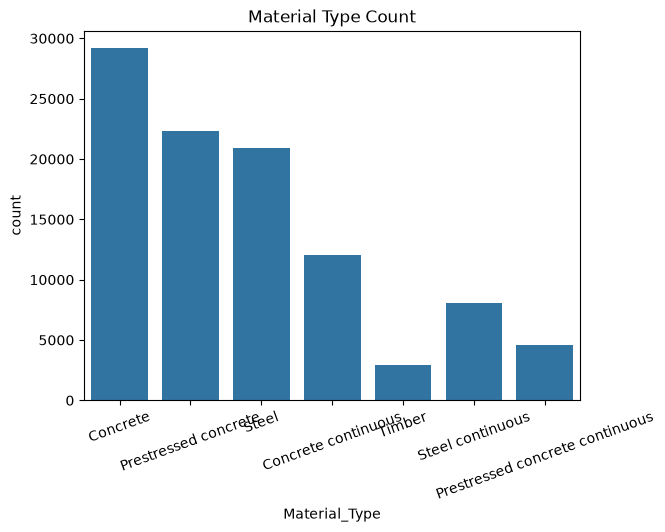

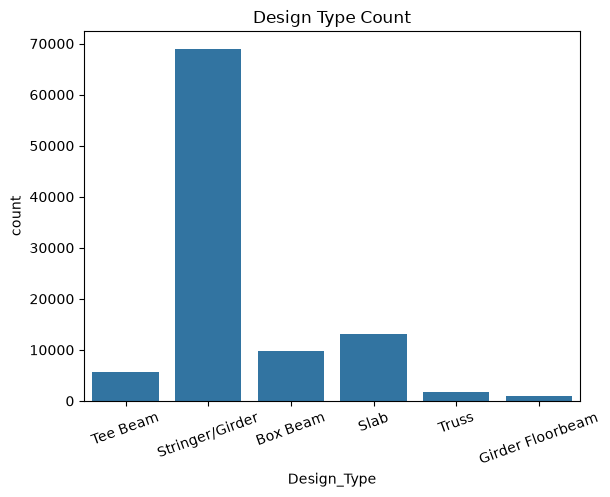

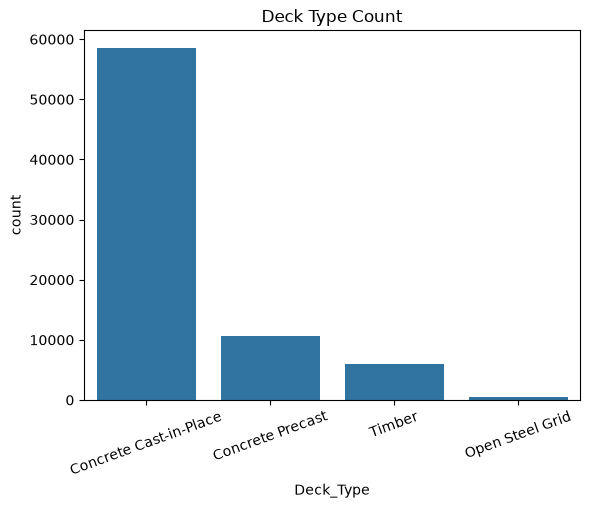

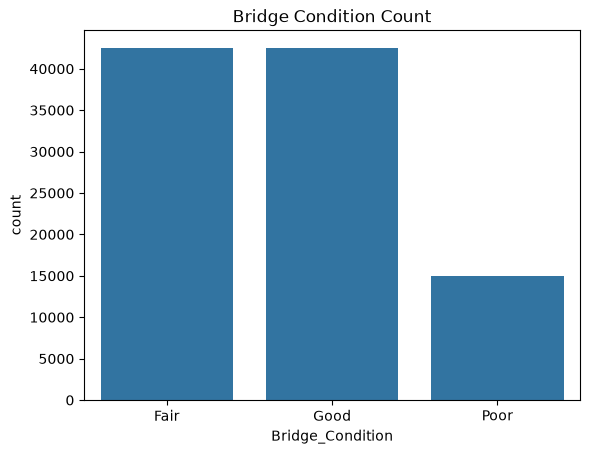

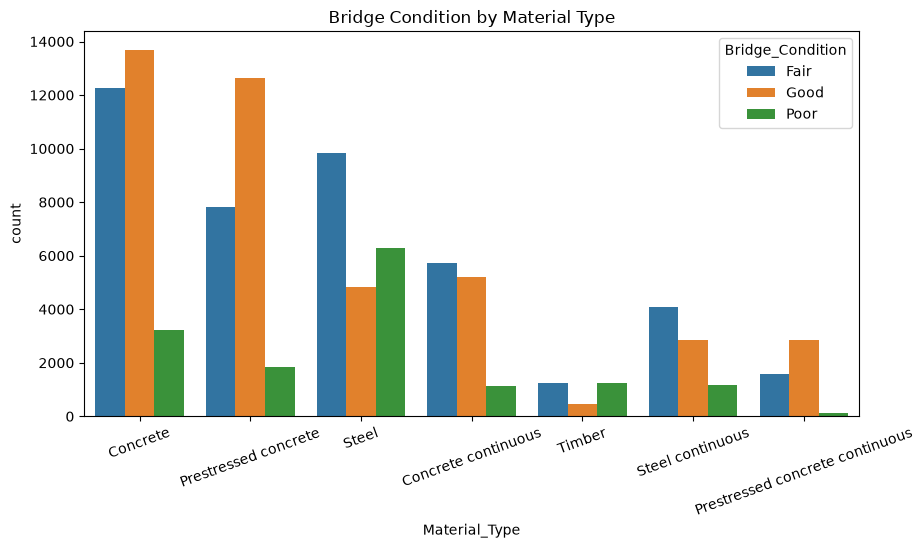

In [5]:
# graph
sns.countplot(x="Material_Type", data=df)
plt.title("Material Type Count")
plt.xticks(rotation=20)
plt.show()

sns.countplot(x="Design_Type", data=df)
plt.title("Design Type Count")
plt.xticks(rotation=20)
plt.show()

sns.countplot(x="Deck_Type", data=df)
plt.title("Deck Type Count")
plt.xticks(rotation=20)
plt.show()

sns.countplot(x="Bridge_Condition", data=df)
plt.title("Bridge Condition Count")
plt.show()

# Material Type vs Bridge Condition
plt.figure(figsize=(10, 5))
sns.countplot(x="Material_Type", hue="Bridge_Condition", data=df)
plt.title("Bridge Condition by Material Type")
plt.xticks(rotation=20)
plt.show()

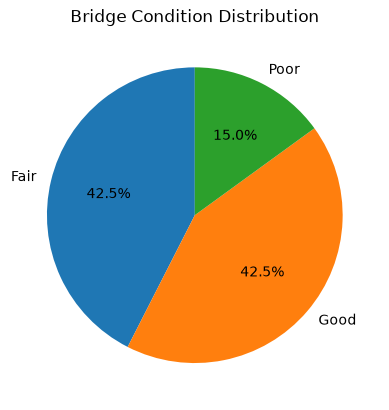

In [6]:
# pie chart of bridge condition
plt.pie(df["Bridge_Condition"].value_counts(), labels=df["Bridge_Condition"].value_counts().index, autopct="%1.1f%%", startangle=90)
plt.title("Bridge Condition Distribution")
plt.show()

In [7]:
# Filling missing values
print(df.isna().sum())

# Numerical columns
df["Year_Reconstructed"] = df["Year_Reconstructed"].fillna(0)
df["Truck_Traffic_Percent"] = df["Truck_Traffic_Percent"].fillna(df["Truck_Traffic_Percent"].median())

# Categorical columns - Era-based (Decade) mode imputation for Deck_Type
df["Build_Decade"] = (df["Year_Built"] // 10) * 10
overall_deck_mode = df["Deck_Type"].mode()[0]
df["Deck_Type"] = df.groupby("Build_Decade")["Deck_Type"].transform(
    lambda group: group.fillna(group.mode()[0] if not group.mode().empty else overall_deck_mode)
)
df.drop(columns=["Build_Decade"], inplace=True)

print(df.isna().sum())
print("*"*100)

# Feature Engineering (for higher model accuracy)
# 1. Bridge Age
df["Bridge_Age"] = 2024 - df["Year_Built"]

# 2. Daily Truck Count
df["Daily_Truck_Count"] = df["Average_Daily_Traffic"] * (df["Truck_Traffic_Percent"] / 100)

print(df[["Year_Built", "Bridge_Age", "Average_Daily_Traffic", "Daily_Truck_Count"]].head())
print("*"*100)

State_Code                   0
Road_Class                   0
Year_Built                   0
Lanes_On_Bridge              0
Average_Daily_Traffic        0
Material_Type                0
Design_Type                  0
Max_Span_Length_m            0
Structure_Length_m           0
Deck_Width_m                 0
Year_Reconstructed       85123
Deck_Type                24470
Truck_Traffic_Percent     4840
Bridge_Condition             0
dtype: int64
State_Code               0
Road_Class               0
Year_Built               0
Lanes_On_Bridge          0
Average_Daily_Traffic    0
Material_Type            0
Design_Type              0
Max_Span_Length_m        0
Structure_Length_m       0
Deck_Width_m             0
Year_Reconstructed       0
Deck_Type                0
Truck_Traffic_Percent    0
Bridge_Condition         0
dtype: int64
****************************************************************************************************
   Year_Built  Bridge_Age  Average_Daily_Traffic  Daily_Truck

<string>:14: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


In [10]:
# encoding
# get dummies
dfe = pd.get_dummies(df[["Material_Type", "Design_Type", "Deck_Type"]], drop_first=True, dtype=int)
df1 = pd.concat([df, dfe], axis=1)
print(df1)

df1 = df1.drop(["Material_Type", "Design_Type", "Deck_Type"], axis=1)
print(df1)
print(df1.isna().sum())

       State_Code  Road_Class  ...  Deck_Type_Open Steel Grid  Deck_Type_Timber
0              47         7.0  ...                          0                 0
1               8         1.0  ...                          0                 0
2              13         2.0  ...                          0                 0
3              16         6.0  ...                          0                 0
4              48         9.0  ...                          0                 0
...           ...         ...  ...                        ...               ...
99995          40         9.0  ...                          0                 0
99996           9        19.0  ...                          0                 0
99997          40         2.0  ...                          0                 0
99998           5        19.0  ...                          0                 0
99999          20         7.0  ...                          0                 0

[100000 rows x 30 columns]
       State

In [11]:
# INPUT
x = df1.drop(["Bridge_Condition"], axis=1)
print(x)

# OUTPUT
y = df1["Bridge_Condition"]
print(y)

print("*"*100)

       State_Code  Road_Class  ...  Deck_Type_Open Steel Grid  Deck_Type_Timber
0              47         7.0  ...                          0                 0
1               8         1.0  ...                          0                 0
2              13         2.0  ...                          0                 0
3              16         6.0  ...                          0                 0
4              48         9.0  ...                          0                 0
...           ...         ...  ...                        ...               ...
99995          40         9.0  ...                          0                 0
99996           9        19.0  ...                          0                 0
99997          40         2.0  ...                          0                 0
99998           5        19.0  ...                          0                 0
99999          20         7.0  ...                          0                 0

[100000 rows x 26 columns]
0        Fai

In [12]:
# train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, stratify=y, random_state=42)

print("Training input shape:", x_train.shape)
print("Testing input shape:", x_test.shape)
print("Training output shape:", y_train.shape)
print("Testing output shape:", y_test.shape)
print("*"*100)

# Scaling
sc = StandardScaler()
sc.fit(x_train)
x_train = sc.transform(x_train)
x_test = sc.transform(x_test)

Training input shape: (80000, 26)
Testing input shape: (20000, 26)
Training output shape: (80000,)
Testing output shape: (20000,)
****************************************************************************************************


In [13]:
# model 1: Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)
acc_dt = accuracy_score(y_test, y_pred_dt)
print(acc_dt)
print(confusion_matrix(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

0.58305
[[4637 2489 1374]
 [2441 5693  366]
 [1300  369 1331]]
              precision    recall  f1-score   support

        Fair       0.55      0.55      0.55      8500
        Good       0.67      0.67      0.67      8500
        Poor       0.43      0.44      0.44      3000

    accuracy                           0.58     20000
   macro avg       0.55      0.55      0.55     20000
weighted avg       0.58      0.58      0.58     20000



Random Forest Accuracy: 0.6676
Training Accuracy: 0.9995
Testing Accuracy: 0.6676
[[5914 1903  683]
 [2184 6247   69]
 [1647  162 1191]]
              precision    recall  f1-score   support

        Fair       0.61      0.70      0.65      8500
        Good       0.75      0.73      0.74      8500
        Poor       0.61      0.40      0.48      3000

    accuracy                           0.67     20000
   macro avg       0.66      0.61      0.62     20000
weighted avg       0.67      0.67      0.66     20000



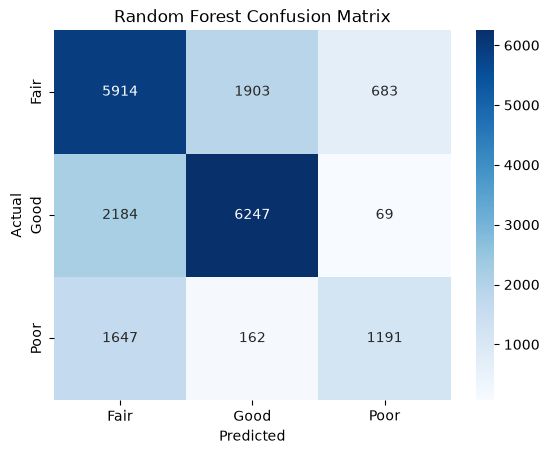

In [14]:
# model 2: Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", acc_rf)

# training vs testing accuracy (check overfitting)
print("Training Accuracy:", rf.score(x_train, y_train))
print("Testing Accuracy:", rf.score(x_test, y_test))

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

# Visual Confusion Matrix with labels
labels = ['Fair', 'Good', 'Poor']
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

                  Feature  Importance
10             Bridge_Age    0.143586
2              Year_Built    0.136275
4   Average_Daily_Traffic    0.092827
6      Structure_Length_m    0.091472
5       Max_Span_Length_m    0.089022
7            Deck_Width_m    0.083296
11      Daily_Truck_Count    0.078727
0              State_Code    0.073681
9   Truck_Traffic_Percent    0.055562
1              Road_Class    0.036560


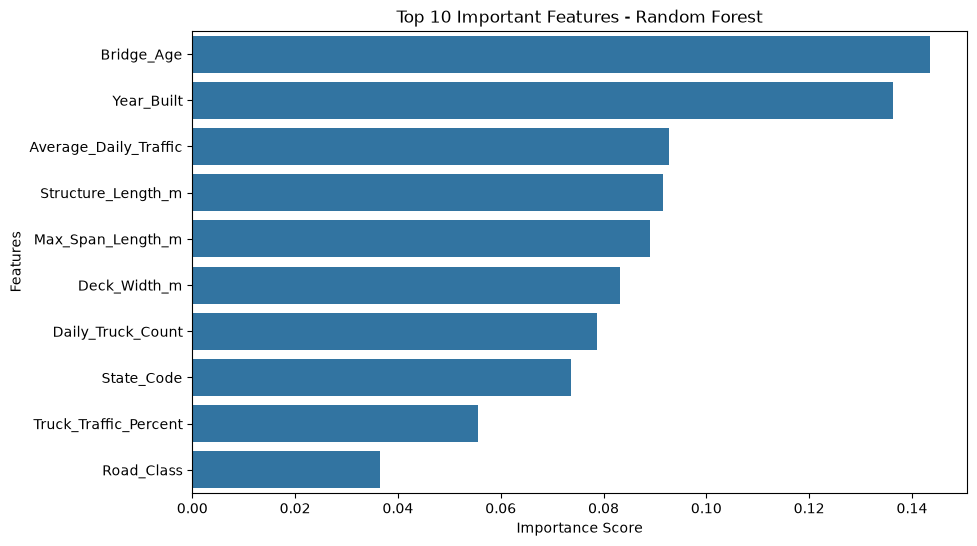

In [15]:
# feature importance
feature_imp = rf.feature_importances_
feature_df = pd.DataFrame({
    'Feature': x.columns,
    'Importance': feature_imp
})
feature_df = feature_df.sort_values(by='Importance', ascending=False)
print(feature_df.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_df.head(10))
plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [16]:
# cross validation
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(rf, x_train, y_train, cv=5, n_jobs=-1)
print("Cross Validation Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

Cross Validation Scores: [0.66375   0.6630625 0.665     0.666     0.668    ]
Mean CV Accuracy: 0.6651625


In [17]:
# model 3: KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)
y_pred_knn = knn.predict(x_test)
acc_knn = accuracy_score(y_test, y_pred_knn)
print(acc_knn)
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

0.6226
[[5422 2227  851]
 [2503 5879  118]
 [1591  258 1151]]
              precision    recall  f1-score   support

        Fair       0.57      0.64      0.60      8500
        Good       0.70      0.69      0.70      8500
        Poor       0.54      0.38      0.45      3000

    accuracy                           0.62     20000
   macro avg       0.61      0.57      0.58     20000
weighted avg       0.62      0.62      0.62     20000



           Model  Accuracy
0  Decision Tree   0.58305
1  Random Forest   0.66760
2            KNN   0.62260


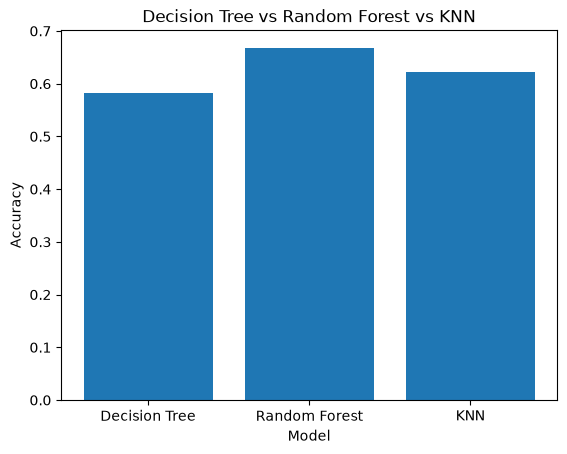

In [18]:
# Model Comparison DataFrame & Bar Chart
df2 = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest", "KNN"],
    "Accuracy": [acc_dt, acc_rf, acc_knn]
})
print(df2)

plt.bar(df2["Model"], df2["Accuracy"])
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Decision Tree vs Random Forest vs KNN")
plt.show()

In [19]:
# prediction on single bridge sample
sample = x_test[0].reshape(1, -1)
pred = rf.predict(sample)
print("Actual Condition:", y_test.iloc[0])
print("Predicted Condition:", pred[0])

Actual Condition: Fair
Predicted Condition: Fair


In [20]:
# Save models
pickle.dump(rf, open("bridge_model.pkl", "wb"))
pickle.dump(sc, open("scaler.pkl", "wb"))
pickle.dump(x.columns.tolist(), open("columns.pkl", "wb"))

# Print unique values for Streamlit dropdowns
print(df["Material_Type"].unique())
print(df["Design_Type"].unique())
print(df["Deck_Type"].unique())
print(df["State_Code"].unique())
print(df["Road_Class"].unique())

<ArrowStringArray>
[                       'Concrete',            'Prestressed concrete',
                           'Steel',             'Concrete continuous',
                          'Timber',                'Steel continuous',
 'Prestressed concrete continuous']
Length: 7, dtype: str
<ArrowStringArray>
['Tee Beam', 'Stringer/Girder', 'Box Beam', 'Slab', 'Truss',
 'Girder Floorbeam']
Length: 6, dtype: str
<ArrowStringArray>
['Concrete Cast-in-Place', 'Concrete Precast', 'Timber', 'Open Steel Grid']
Length: 4, dtype: str
[47  8 13 16 48 40 17 22 26 37 42 36 19 46 28 29  6 39 33  4 27 31 34 54
 21 53  1 12 15 51 23 11 56 20 55 41  5 18 72 49 45 38 35 32  9 25 30 24
 44 66 50 10  2 78]
[ 7.  1.  2.  6.  9. 17. 11. 19.  8. 16. 14. 12.]
